# Projeto 05 — Credit Risk Model Stability
## 02 · Engenharia de features e Master Table

**Objetivo.** Transformar as tabelas relacionais em uma tabela com **1 linha por `case_id`**,
pronta para modelagem, em que toda feature (i) tem uma hipótese de negócio e (ii) usa apenas
informação que existia em `date_decision`.

**Roteiro.**

1. Ponto de observação: as datas das tabelas estão no mesmo calendário de `date_decision`?
2. Das tabelas às features, fonte por fonte (hipótese → regra → código).
3. Tabela candidata: LEFT JOIN e granularidade.
4. Diagnóstico no TRAIN: missing, estabilidade, IV, redundância; investigação das mais fortes.
5. Decisões: tabela de auditoria e catálogo de features.
6. Master Table: QA final e gravação.
7. Checklist da seção 12 do enunciado.

Nenhum modelo é treinado. O que envolve target (IV) ou distribuição de features é calculado
**só no TRAIN**; as regras de cálculo são fórmulas fixas aplicadas igualmente a TRAIN, TEST e OOT.

## 0. Preparação

In [1]:
import sys
from datetime import date
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # o notebook roda a partir de notebooks/

import pandas as pd
import polars as pl

from src import audit, plots
from src.catalog import (
    AUTHORED, CANDIDATE_FEATURES, INVESTIGATED, KEEP, SELECTED_FEATURES, SPECS, catalog_frame, combined_features,
    features_of,
)
from src.config import (
    CASE_ID, DATE_AUDIT_PATH, DATE_DECISION, DATE_SHIFT_DAYS, FEATURE_CATALOG_PATH, FIGURES_DIR, MASTER_QA_PATH,
    MASTER_TABLE_PATH, MONTH, RANDOM_STATE, SPLIT, TARGET, TRAIN,
)
from src.data import load_base, scan_source
from src.features import TAX_REGISTRIES, build_candidate_table, build_master_table
from src.iv import MISSING_LABEL, information_value
from src.qa import assert_all_passed, check_master_table
from src.split import assign_split

plots.apply_style()
pd.set_option("display.max_columns", 50, "display.max_colwidth", 140, "display.width", 220, "display.max_rows", 100)

raw_base = load_base()
base = assign_split(raw_base)
train = base.filter(pl.col(SPLIT) == TRAIN)
train_ids = train.lazy().select(CASE_ID, DATE_DECISION)
print(f"Python {sys.version.split()[0]} | polars {pl.__version__} | pandas {pd.__version__}")
print(base.group_by(SPLIT).len().sort(SPLIT).to_pandas().set_index(SPLIT)["len"].to_dict())

Python 3.11.9 | polars 2.0.0 | pandas 3.0.5
{'OOT': 150240, 'TEST': 275284, 'TRAIN': 1101135}


## 1. Ponto de observação: cada informação existia em `date_decision`?

A regra de ouro do projeto: o modelo simula uma decisão tomada em `date_decision`; nada datado
depois disso pode entrar. O primeiro teste é direto: comparar **todas** as colunas de data das
fontes escolhidas com `date_decision`, no TRAIN.

### 1.1 Auditoria direta: as datas como estão gravadas

In [2]:
USED_SOURCES = ["static_0", "static_cb_0", "person_1", "applprev_1", "credit_bureau_a_1", *TAX_REGISTRIES]
date_audit = audit.date_audit(train, USED_SOURCES)

suspicious = date_audit[date_audit["apos_decisao_bruto"] > 0.01].sort_values("apos_decisao_bruto", ascending=False)
display(suspicious[["fonte", "coluna", "n_valores", "apos_decisao_bruto", "maior_avanco_dias"]]
        .style.format({"n_valores": "{:,}", "apos_decisao_bruto": "{:.1%}"}).hide(axis="index"))

fonte,coluna,n_valores,apos_decisao_bruto,maior_avanco_dias
static_cb_0,assignmentdate_4527235D,"91,598",100.0%,14
static_cb_0,responsedate_4527233D,"526,414",100.0%,14
tax_registry_a_1,recorddate_4527225D,"2,609,650",100.0%,14
static_cb_0,responsedate_4917613D,"62,873",99.7%,14
static_cb_0,responsedate_1012D,"575,866",99.7%,14
credit_bureau_a_1,dateofcredend_289D,"1,911,993",98.9%,28697
static_0,lastrepayingdate_696D,"1,822",82.5%,13
credit_bureau_a_1,lastupdate_1112D,"1,911,993",66.3%,14
credit_bureau_a_1,refreshdate_3813885D,"7,939,386",51.6%,14
static_0,validfrom_1069D,"121,516",36.1%,14


Lidas ao pé da letra, as tabelas estariam cheias de futuro: **100% das deduções fiscais do
fornecedor A**, praticamente todas as datas de resposta da autoridade fiscal, dois terços das
atualizações de contratos no bureau e 2% dos "pedidos anteriores" teriam data **posterior** à
decisão. Antes de concluir que é leakage (e filtrar esses registros), vale olhar o formato do
problema: a coluna `maior_avanco_dias` mostra que, tirando as datas contratuais (fim previsto de
contrato, vencimento de parcela), nenhum evento passa de **exatamente 14 dias** depois da decisão.

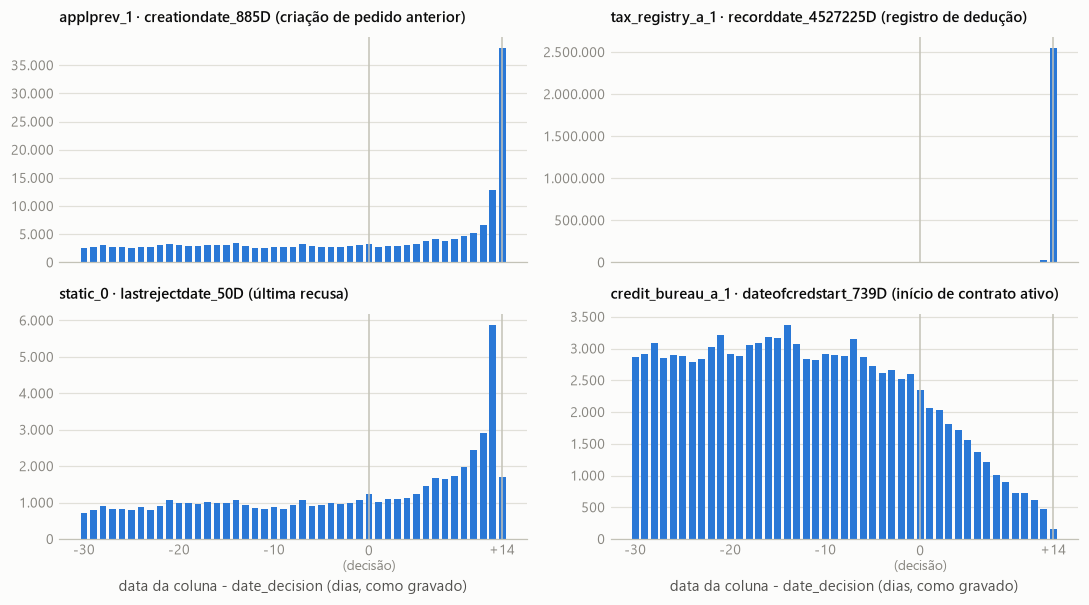

In [3]:
histograms = {
    "applprev_1 · creationdate_885D (criação de pedido anterior)":
        audit.offset_histogram(train, "applprev_1", "creationdate_885D"),
    "tax_registry_a_1 · recorddate_4527225D (registro de dedução)":
        audit.offset_histogram(train, "tax_registry_a_1", "recorddate_4527225D"),
    "static_0 · lastrejectdate_50D (última recusa)":
        audit.offset_histogram(train, "static_0", "lastrejectdate_50D"),
    "credit_bureau_a_1 · dateofcredstart_739D (início de contrato ativo)":
        audit.offset_histogram(train, "credit_bureau_a_1", "dateofcredstart_739D"),
}
fig = plots.plot_offset_histograms(histograms, DATE_SHIFT_DAYS)
plots.save_figure(fig, FIGURES_DIR / "date_offsets_raw.png")

**Leitura.** Em fontes independentes (dado interno, registro fiscal, bureau) os eventos terminam
no mesmo ponto, +14 dias, sem nenhum registro além dele. E o formato é o de um "hoje", não o de
uma janela de 14 dias de futuro: os registros de dedução se **acumulam** no dia +14 (é o dia da
consulta), os pedidos e as recusas crescem até +13/+14 (tentativas nos dias anteriores ao pedido
aprovado) e os contratos novos no bureau vão rareando até +14 (o bureau demora a registrar o que
acabou de ser aberto). Uma extração feita 14 dias depois da decisão não teria por que concentrar
eventos justamente no último dia.

Hipótese: **o calendário das tabelas secundárias está 14 dias adiantado em relação ao de
`date_decision`**. A descrição oficial do dataset diz que as colunas de sufixo `D` passaram por
uma "transformação de data", sem dizer qual. Dá para testar com feriados.

### 1.2 Evidência: feriados e dias do mês caem 14 dias depois

`date_decision` e `creationdate_885D` registram o mesmo tipo de evento no mesmo credor (um pedido
de crédito). Se os dois calendários fossem o mesmo, o vale do Ano Novo cairia no mesmo dia.

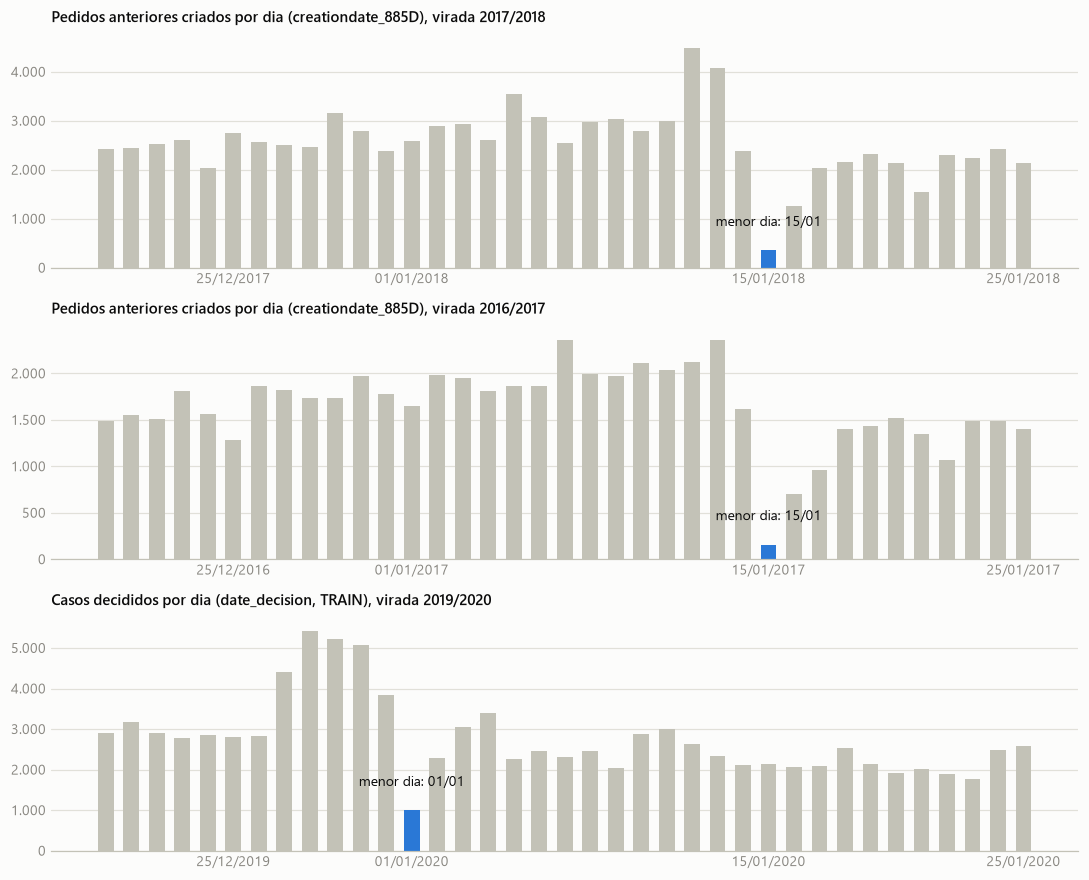

In [4]:
created = scan_source("applprev_1").join(train_ids, on=CASE_ID).select("creationdate_885D").collect().to_series()
panels = {
    "Pedidos anteriores criados por dia (creationdate_885D), virada 2017/2018":
        audit.daily_counts(created, date(2017, 12, 20), date(2018, 1, 25)),
    "Pedidos anteriores criados por dia (creationdate_885D), virada 2016/2017":
        audit.daily_counts(created, date(2016, 12, 20), date(2017, 1, 25)),
    "Casos decididos por dia (date_decision, TRAIN), virada 2019/2020":
        audit.daily_counts(train[DATE_DECISION], date(2019, 12, 20), date(2020, 1, 25)),
}
fig = plots.plot_holiday_dips(panels)
plots.save_figure(fig, FIGURES_DIR / "calendar_offset_new_year.png")

In [5]:
employment_start = (
    scan_source("person_1").filter(pl.col("num_group1") == 0).join(train_ids, on=CASE_ID)
    .select(pl.col("empl_employedfrom_271D").drop_nulls().dt.day().alias("dia do mês"))
    .collect().to_series().value_counts(normalize=True, sort=True).head(3)
)
print("empl_employedfrom_271D (início do emprego, solicitante): dias do mês mais frequentes")
display(employment_start.to_pandas().style.format({"proportion": "{:.1%}"}).hide(axis="index"))

empl_employedfrom_271D (início do emprego, solicitante): dias do mês mais frequentes


dia do mês,proportion
15,86.6%
16,2.2%
19,1.6%


**Leitura.**

- Nas decisões, o dia mais fraco da virada é **1º de janeiro**. Nos pedidos anteriores do mesmo
  credor, em dois anos diferentes, o dia mais fraco é **15 de janeiro**: 14 dias depois.
- A data de início do emprego é declarada pelo cliente e normalmente só tem mês e ano; o natural
  seria o sistema gravar o dia 1. Ela cai no dia **15** em quase 9 de cada 10 casos: 1 + 14.

São duas assinaturas de calendário independentes apontando o mesmo deslocamento.

### 1.3 Os campos de ano e mês estão 1 mês adiantados

Algumas datas vêm separadas em ano e mês (sufixo `T`), como a do maior atraso de um contrato no
bureau e a de cada pagamento mensal. Um mês não pode ser deslocado em 14 dias, então é preciso
medir o deslocamento delas à parte. Dois cruzamentos, sempre entre campos que descrevem o mesmo
evento:

1. em `credit_bureau_a_1`, o (ano, mês) do maior valor em atraso de um contrato ativo contra a
   data, em dia, desse mesmo máximo;
2. em `credit_bureau_a_2`, o último mês com pagamento reportado de cada contrato ativo contra a
   data da última atualização do contrato em `credit_bureau_a_1`.

In [6]:
same_event = (
    scan_source("credit_bureau_a_1").join(train_ids, on=CASE_ID)
    .filter(pl.col("overdueamountmax2_14A") == pl.col("overdueamountmax_155A"))  # os dois campos falam do mesmo máximo
)
overdue_fields = ("overdueamountmaxdateyear_2T", "overdueamountmaxdatemonth_365T", "overdueamountmax2date_1142D")
year_month_check = pd.DataFrame({
    "datas como gravadas": audit.year_month_offset(same_event, *overdue_fields, shift_days=0),
    "datas menos 14 dias": audit.year_month_offset(same_event, *overdue_fields, shift_days=DATE_SHIFT_DAYS),
}).fillna(0).loc[-1:2]
year_month_check.index.name = "(ano, mês) - mês da data (meses)"
display(year_month_check.style.format("{:.1%}"))

,datas como gravadas,datas menos 14 dias
"(ano, mês) - mês da data (meses)",,
-1,1.4%,0.6%
0,52.0%,6.9%
1,43.3%,89.3%


In [7]:
sample_ids = train.sample(fraction=0.03, seed=RANDOM_STATE).lazy().select(CASE_ID)
last_reported = (
    scan_source("credit_bureau_a_2").filter(pl.col("pmts_dpd_1073P").is_not_null())
    .join(sample_ids, on=CASE_ID, how="semi")
    .group_by(CASE_ID, "num_group1")
    .agg((pl.col("pmts_year_1139T") * 12 + pl.col("pmts_month_158T")).max().cast(pl.Int32).alias("ultimo_mes_reportado"))
)
last_update = (
    scan_source("credit_bureau_a_1").filter(pl.col("lastupdate_1112D").is_not_null())
    .join(sample_ids, on=CASE_ID, how="semi")
    .select(CASE_ID, "num_group1", (pl.col("lastupdate_1112D") - pl.duration(days=DATE_SHIFT_DAYS)).alias("atualizacao"))
)
payment_check = (
    last_reported.join(last_update, on=[CASE_ID, "num_group1"])
    .select((pl.col("ultimo_mes_reportado") - (pl.col("atualizacao").dt.year() * 12 + pl.col("atualizacao").dt.month())).alias("meses"))
    .collect(engine="streaming").to_series().value_counts(normalize=True, sort=True)
)
print("credit_bureau_a_2: último mês reportado - mês da última atualização do contrato (amostra de 3% dos casos do TRAIN)")
display(payment_check.to_pandas().head(3).style.format({"proportion": "{:.2%}"}).hide(axis="index"))

credit_bureau_a_2: último mês reportado - mês da última atualização do contrato (amostra de 3% dos casos do TRAIN)


meses,proportion
1,99.99%
-13,0.00%
-12,0.00%


**Leitura.** Com as datas corrigidas em 14 dias, o (ano, mês) fica **1 mês à frente** em cerca de
9 de cada 10 contratos; sem a correção, o resultado se divide em dois, que é exatamente o que um
deslocamento de 14 dias produz ao atravessar a virada do mês. E em `credit_bureau_a_2` a relação
é praticamente exata: em 99,99% dos contratos, o último mês com pagamento reportado é o mês
seguinte ao da última atualização. Os campos de ano e mês estão, portanto, **1 mês adiantados**;
e como a última atualização nunca passa da decisão, o histórico de pagamentos termina, no máximo,
no mês da decisão.

### 1.4 Regra adotada e auditoria no calendário corrigido

| Tipo de campo | Como está gravado | Tempo até a decisão |
|---|---|---|
| data em dia (sufixo `D`) | 14 dias adiantada | `date_decision - (data - 14 dias)` |
| par (ano, mês) (sufixo `T`) | 1 mês adiantado | `mês da decisão - (ano/mês - 1 mês)` |

Os dois deslocamentos são constantes em `src/config.py` (`DATE_SHIFT_DAYS`, `MONTH_SHIFT`) e todo
cálculo de tempo passa por duas funções de `src/features.py` (`days_before_decision`,
`months_before_decision`). O corte é aplicado **no código, antes de agregar**: registro com tempo
negativo (depois da decisão) é descartado. A auditoria abaixo refaz a comparação nesse calendário.

In [8]:
USED_DATE_COLUMNS = [
    "lastdelinqdate_224D", "lastrejectdate_50D", "empl_employedfrom_271D", "creationdate_885D", "dateactivated_425D",
    "dateofcredstart_739D", "dateofcredstart_181D", *[columns["date"] for columns in TAX_REGISTRIES.values()],
]
date_audit["usada_em_feature"] = date_audit["coluna"].isin(USED_DATE_COLUMNS)
DATE_AUDIT_PATH.parent.mkdir(parents=True, exist_ok=True)
date_audit.to_csv(DATE_AUDIT_PATH, index=False)

still_after = date_audit[date_audit["n_apos_corrigido"] > 0]
print(f"Colunas de data auditadas: {len(date_audit)} | com algum valor depois da decisão no calendário corrigido: {len(still_after)}")
display(still_after[["fonte", "coluna", "n_valores", "n_apos_corrigido", "maior_avanco_dias", "usada_em_feature"]]
        .style.format({"n_valores": "{:,}", "n_apos_corrigido": "{:,}"}).hide(axis="index"))

used = date_audit[date_audit["usada_em_feature"]]
assert set(used["coluna"]) == set(USED_DATE_COLUMNS) and (used["n_apos_corrigido"] == 0).all()
print(f"Datas usadas em features: {len(used)} colunas, {used['n_valores'].sum():,} valores no TRAIN, "
      f"{used['n_apos_corrigido'].sum()} depois da decisão no calendário corrigido.")
display(used[["fonte", "coluna", "n_valores", "apos_decisao_bruto", "maior_avanco_dias", "n_apos_corrigido"]]
        .style.format({"n_valores": "{:,}", "apos_decisao_bruto": "{:.1%}"}).hide(axis="index"))

Colunas de data auditadas: 49 | com algum valor depois da decisão no calendário corrigido: 5


fonte,coluna,n_valores,n_apos_corrigido,maior_avanco_dias,usada_em_feature
static_0,firstdatedue_489D,"743,890","2,518",47,False
applprev_1,firstnonzeroinstldate_307D,"4,101,673","116,059",47,False
credit_bureau_a_1,dateofcredend_289D,"1,911,993","1,868,389",28697,False
credit_bureau_a_1,dateofcredend_353D,"4,567,184","298,116",28796,False
credit_bureau_a_1,dateofrealrepmt_138D,"4,540,778",475,28658,False


Datas usadas em features: 10 colunas, 20,340,738 valores no TRAIN, 0 depois da decisão no calendário corrigido.


fonte,coluna,n_valores,apos_decisao_bruto,maior_avanco_dias,n_apos_corrigido
static_0,lastdelinqdate_224D,"384,741",5.4%,13,0
static_0,lastrejectdate_50D,"537,018",5.0%,14,0
person_1,empl_employedfrom_271D,"424,830",0.1%,13,0
applprev_1,creationdate_885D,"4,549,195",2.2%,14,0
applprev_1,dateactivated_425D,"2,361,888",0.5%,14,0
credit_bureau_a_1,dateofcredstart_181D,"4,567,192",0.0%,13,0
credit_bureau_a_1,dateofcredstart_739D,"1,911,993",0.9%,14,0
tax_registry_a_1,recorddate_4527225D,"2,609,650",100.0%,14,0
tax_registry_b_1,deductiondate_4917603D,"319,294",7.6%,13,0
tax_registry_c_1,processingdate_168D,"2,674,937",21.7%,14,0


**Leitura.**

- No calendário corrigido, **nenhuma** das datas usadas nas features tem valor depois da decisão.
  O filtro de corte continua no código, mas não descarta nada: os dados são um retrato tirado no
  dia da decisão.
- As únicas colunas que ainda passam da decisão são datas **contratuais** (fim previsto de
  contrato, primeiro vencimento) e uma data de encerramento com valores absurdos (dezenas de
  milhares de dias à frente). Nenhuma delas é usada.
- O que a regra literal faria: `data <= date_decision`, sem a correção, jogaria fora os 14 dias
  **mais recentes** de histórico (2% dos pedidos anteriores, todo o registro fiscal do fornecedor
  A) e erraria todas as recências em 14 dias. Não evitaria leakage nenhum, porque não há registro
  posterior à decisão para evitar.

Se o avaliador preferir a leitura literal, basta trocar `DATE_SHIFT_DAYS` e `MONTH_SHIFT` para 0
em `src/config.py` e reexecutar este notebook: o corte passa a descartar esses registros.

### 1.5 O contrato em análise aparece nos históricos?

Mesmo sem registros futuros, um histórico poderia conter o **próprio contrato** que estamos
tentando prever, com o seu desfecho. Dois lugares onde isso poderia acontecer:

In [9]:
same_day = (
    scan_source("applprev_1").join(train_ids, on=CASE_ID)
    .filter(pl.col("creationdate_885D") - pl.duration(days=DATE_SHIFT_DAYS) == pl.col(DATE_DECISION))
    .select(
        pl.len().alias("pedidos criados no dia da decisão"),
        pl.col(CASE_ID).n_unique().alias("casos"),
        pl.col("dateactivated_425D").is_not_null().mean().alias("viraram contrato"),
        (pl.col("maxdpdtolerance_577P") > 0).fill_null(False).mean().alias("com algum atraso registrado"),
    ).collect()
)
display(same_day.to_pandas().style.format({"pedidos criados no dia da decisão": "{:,}", "casos": "{:,}",
                                           "viraram contrato": "{:.1%}", "com algum atraso registrado": "{:.2%}"}).hide(axis="index"))

new_in_bureau = (
    scan_source("credit_bureau_a_1").join(train_ids, on=CASE_ID)
    .filter((pl.col(DATE_DECISION) - (pl.col("dateofcredstart_739D") - pl.duration(days=DATE_SHIFT_DAYS))).dt.total_days() <= 1)
    .select(
        pl.len().alias("contratos ativos abertos até 1 dia antes da decisão"),
        (pl.col("financialinstitution_591M") == "Home Credit").sum().alias("do próprio credor"),
        (pl.col("dpdmax_139P") > 0).sum().alias("com atraso"),
    ).collect()
)
display(new_in_bureau.to_pandas().style.hide(axis="index"))

pedidos criados no dia da decisão,casos,viraram contrato,com algum atraso registrado
"38,054","35,368",1.1%,0.29%


contratos ativos abertos até 1 dia antes da decisão,do próprio credor,com atraso
630,0,0


**Leitura.**

- Os "pedidos anteriores" criados no próprio dia da decisão são tentativas paralelas que não
  viraram contrato (cerca de 1% foi ativado), quase todas canceladas ou recusadas. Não são o
  contrato aprovado e praticamente não trazem comportamento de pagamento: 0,3% têm algum atraso
  registrado, o que nem deveria ser possível para um pedido criado no dia. São poucos demais para
  mexer nas agregações, mas ficam anotados como ruído do dado.
- No bureau, nenhum contrato recém-aberto é do próprio credor e nenhum tem atraso: o contrato em
  análise ainda não foi reportado. Os que aparecem são créditos tomados em **outras** instituições
  na véspera ou no dia, informação legítima (e relevante) no momento da decisão.

## 2. Das tabelas às features

Cada bloco abaixo mostra a hipótese e a regra de cada feature candidata (do catálogo em
`src/catalog.py`); o cálculo está em `src/features.py`. São 74 candidatas; a seção 5 decide quais
ficam.

### 2.1 `static_0` e `static_cb_0` (depth 0): join direto e seleção de colunas

`static_0` tem 167 colunas. Não entram todas: foram escolhidas por família de hipótese (o pedido
em análise, a dívida com o credor, o comportamento de pagamento, a procura recente por crédito,
contatos compartilhados), evitando as constantes, as quase vazias e as que mudam de regime vistas
no notebook 01. De `static_cb_0` entram só as consultas ao bureau.

In [10]:
display(features_of("static_0").style.hide(axis="index"))
display(features_of("static_cb_0").style.hide(axis="index"))

feature,tipo,regra_de_calculo,hipotese_de_negocio
credamount_770A,original,coluna original,valores maiores expõem mais o cliente e o credor
annuity_780A,original,coluna original,"parcela mensal: quanto maior, maior o esforço de pagamento"
pmtnum_254L,original,coluna original (número de parcelas),prazos longos dão mais tempo para a situação do cliente piorar
eir_270L,original,coluna original (taxa de juros efetiva),a taxa reflete o risco que o credor já enxergava e encarece a dívida
credtype_322L,original,"coluna original (COL = bens, CAL = dinheiro, REL = rotativo)",produtos diferentes atraem perfis de risco diferentes
totaldebt_9A,original,coluna original,dívida já existente com o credor reduz a folga para a nova parcela
annuitynextmonth_57A,original,coluna original,parcelas já comprometidas no próximo mês
avgdpdtolclosure24_3658938P,original,coluna original,atraso médio nos últimos 24 meses: hábito de pagar atrasado
pctinstlsallpaidlate1d_3546856L,original,coluna original,proporção de parcelas pagas com atraso: frequência do atraso
pctinstlsallpaidlat10d_839L,original,coluna original,proporção de parcelas com 10+ dias de atraso: atraso que não é esquecimento


feature,tipo,regra_de_calculo,hipotese_de_negocio
days30_165L,original,coluna original,consultas ao bureau em 30 dias: busca imediata por crédito
days120_123L,original,coluna original,consultas ao bureau em 120 dias
days360_512L,original,coluna original,consultas ao bureau em 360 dias: apetite por crédito no ano
cb_queries_30d_share,autoral,days30_165L / days360_512L,consultas concentradas no último mês indicam aceleração da busca por crédito


### 2.2 `person_1` (depth 1): só a linha do solicitante

A linha `num_group1 = 0` é o cliente; as outras são contatos. A idade sai da data de nascimento,
que vem truncada no dia 1 do mês (o deslocamento de 14 dias é irrelevante na escala de anos).
**Sexo não foi incluído**: é um atributo protegido, difícil de defender numa decisão de crédito.

In [11]:
display(features_of("person_1").style.hide(axis="index"))

feature,tipo,regra_de_calculo,hipotese_de_negocio
mainoccupationinc_384A,original,"coluna original, linha do solicitante",renda declarada: base da capacidade de pagamento
incometype_1044T,original,"coluna original, linha do solicitante",aposentados e servidores têm renda mais estável do que autônomos
education_927M,original,"coluna original, com o código de ausente convertido em nulo",escolaridade se associa a estabilidade de renda
age_years,autoral,"(date_decision - birth_259D) / 365,25",clientes mais velhos têm renda e histórico mais estáveis
employment_years,autoral,"(date_decision - empl_employedfrom_271D) / 365,25, no calendário corrigido",mais tempo no emprego = renda mais estável


### 2.3 `applprev_1` (depth 1): pedidos anteriores ao credor

O status de cada pedido é um código de uma letra sem dicionário. O significado foi inferido do
que acompanha cada código:

In [12]:
missing_code = pl.lit("a55475b1")
status_meaning = (
    scan_source("applprev_1").join(train_ids, on=CASE_ID).group_by("status_219L").agg(
        pl.len().alias("pedidos"),
        pl.col("dateactivated_425D").is_not_null().mean().alias("com data de ativação"),
        (pl.col("rejectreason_755M") != missing_code).mean().alias("com motivo de recusa"),
        (pl.col("cancelreason_3545846M") != missing_code).mean().alias("com motivo de cancelamento"),
        (pl.col("outstandingdebt_522A") > 0).mean().alias("com dívida em aberto"),
        pl.col("dtlastpmt_581D").is_not_null().mean().alias("com último pagamento"),
    ).sort("pedidos", descending=True).head(4).collect()
)
display(status_meaning.to_pandas().style.format({"pedidos": "{:,}", **{column: "{:.0%}" for column in status_meaning.columns[2:]}}).hide(axis="index"))

status_219L,pedidos,com data de ativação,com motivo de recusa,com motivo de cancelamento,com dívida em aberto,com último pagamento
D,"1,858,950",0%,61%,61%,0%,0%
K,"1,852,910",100%,4%,0%,0%,66%
A,"501,807",100%,10%,0%,82%,0%
T,"306,832",1%,11%,92%,0%,0%


`D` nunca é ativado e é o único com motivo de recusa na maioria dos casos: **recusado**. `K` foi
ativado, não tem dívida e tem último pagamento: **quitado**. `A` foi ativado e tem dívida em
aberto: **ativo**. `T` não foi ativado e tem motivo de cancelamento: **cancelado**. Para não
depender dos códigos além do necessário, "virou contrato" é definido pela data de ativação, e só
`D` é usado como rótulo (recusa).

Quem não tem linha em `applprev_1` não tem pedido anterior (no TRAIN, a ausência coincide em 100%
dos casos com `lastapplicationdate_877D` nula em `static_0`), então as **contagens** valem 0; as
demais agregações ficam nulas (não há o que medir).

In [13]:
display(features_of("applprev_1").style.hide(axis="index"))

feature,tipo,regra_de_calculo,hipotese_de_negocio
prev_n_applications,autoral,quantidade de pedidos anteriores (0 se não há),muitos pedidos indicam dependência de crédito
prev_n_contracts,autoral,pedidos anteriores que viraram contrato (dateactivated_425D preenchida),contratos já firmados = relacionamento conhecido pelo credor
prev_share_rejected,autoral,pedidos recusados (status D) / pedidos anteriores,quem foi recusado muitas vezes já foi visto como arriscado
prev_days_since_last_application,autoral,"menor (date_decision - creationdate_885D), calendário corrigido",pedido muito recente indica urgência ou tentativas repetidas
prev_years_since_first_application,autoral,"maior (date_decision - creationdate_885D) / 365,25",tempo de relacionamento com o credor
prev_n_applications_3m,autoral,pedidos criados nos 90 dias antes da decisão,aceleração recente da procura por crédito
prev_n_applications_12m,autoral,pedidos criados nos 365 dias antes da decisão,procura por crédito no último ano
prev_n_rejected_12m,autoral,pedidos recusados (status D) criados nos 365 dias antes da decisão,recusas recentes mostram que o risco já foi percebido há pouco
prev_max_dpd,autoral,maior maxdpdtolerance_577P entre os contratos anteriores,maior atraso já observado com o credor
prev_share_contracts_dpd,autoral,contratos com maxdpdtolerance_577P > 0 / contratos com atraso conhecido,"atrasar em vários contratos é hábito, não acidente"


### 2.4 `credit_bureau_a_1` (depth 1): contratos em outras instituições

Cada linha carrega um contrato ativo e um encerrado lado a lado (notebook 01, seção 7), então as
duas listas são agregadas em separado. Há uma armadilha de disponibilidade: **nos cinco primeiros
meses de 2019 o bureau informa quantos contratos encerrados o cliente tem, mas não envia os
contratos**.

In [14]:
bureau_by_month = (
    scan_source("credit_bureau_a_1").join(train.lazy().select(CASE_ID, MONTH), on=CASE_ID)
    .group_by(CASE_ID, MONTH).agg(
        (pl.col("numberofcontrsvalue_358L").max().fill_null(0) > 0).alias("bureau conta encerrados"),
        pl.col("dateofcredstart_181D").is_not_null().any().alias("bureau envia encerrados"),
    )
    .group_by(MONTH).agg(pl.len().alias("casos com bureau"), pl.col("bureau conta encerrados").mean(), pl.col("bureau envia encerrados").mean())
    .sort(MONTH).collect(engine="streaming")
)
display(bureau_by_month.to_pandas().set_index(MONTH).T.style.format("{:.0%}", subset=pd.IndexSlice[["bureau conta encerrados", "bureau envia encerrados"], :])
        .format("{:,.0f}", subset=pd.IndexSlice[["casos com bureau"], :]))

MONTH,201901,201902,201903,201904,201905,201906,201907,201908,201909,201910,201911,201912,202001,202002,202003,202004,202005,202006
casos com bureau,"33,230","40,965","45,489","47,359","42,911","71,056","72,975","74,769","74,298","71,640","88,061","95,711","65,606","58,016","47,006","6,465","22,034","35,377"
bureau conta encerrados,83%,86%,89%,85%,86%,86%,87%,87%,87%,88%,87%,88%,87%,92%,94%,93%,94%,94%
bureau envia encerrados,0%,0%,23%,0%,1%,85%,85%,86%,87%,88%,87%,88%,87%,92%,94%,93%,94%,94%


De janeiro a maio de 2019, cerca de 85% dos casos com bureau têm contratos encerrados segundo o
próprio bureau, mas quase nenhum registro deles chega (só uma parte em março). A partir de junho
de 2019 as duas linhas coincidem. Uma "proporção de contratos com atraso" calculada só com os
ativos teria outro significado nesses meses. Duas regras resolvem isso:

- a **quantidade de contratos encerrados** vem do total informado pelo bureau, que existe em todo
  o período;
- as features que **precisam do detalhe dos encerrados** ficam **nulas** quando o bureau conta
  encerrados e não envia nenhum (melhor desconhecido do que um número com outro significado).

In [15]:
display(features_of("credit_bureau_a_1").style.hide(axis="index"))

feature,tipo,regra_de_calculo,hipotese_de_negocio
cb_n_active_contracts,autoral,quantidade de contratos ativos no bureau,muitos contratos simultâneos pressionam o orçamento
cb_n_closed_contracts,autoral,contratos encerrados informados pelo bureau (numberofcontrsvalue_358L; 0 se o bureau respondeu sem nenhum),contratos encerrados mostram experiência de crédito concluída
cb_active_debt,autoral,totaloutstanddebtvalue_39A (total do bureau para os contratos ativos),dívida em aberto em outras instituições
cb_active_monthly_instalment,autoral,soma de monthlyinstlamount_332A dos contratos ativos,parcelas mensais já comprometidas em outras instituições
cb_active_overdue_amount,autoral,soma de overdueamount_659A dos contratos ativos,estar inadimplente agora em outro credor é o sinal mais direto de dificuldade
cb_active_max_dpd,autoral,maior dpdmax_139P entre os contratos ativos,gravidade do atraso nos contratos em andamento
cb_closed_max_dpd,autoral,maior dpdmax_757P entre os contratos encerrados,gravidade do atraso em contratos já encerrados
cb_share_contracts_dpd,autoral,contratos (ativos + encerrados) com atraso máximo > 0 / contratos com atraso conhecido; nula se o bureau informa contratos encerrados mas não envia o detalhe deles,atrasar em muitos contratos é padrão de comportamento
cb_years_since_first_credit,autoral,"maior (date_decision - início do contrato) / 365,25; nula se o bureau informa contratos encerrados mas não envia o detalhe deles",histórico de crédito longo dá mais evidência e costuma indicar menor risco
cb_days_since_last_credit,autoral,"menor (date_decision - início do contrato), calendário corrigido; nula se o bureau informa contratos encerrados mas não envia o detalhe deles",crédito aberto dias antes em outro credor indica acúmulo de dívidas


### 2.5 `credit_bureau_a_2` (depth 2): pagamentos mês a mês, em janelas

É a maior tabela (188 milhões de linhas) e a única de depth 2 usada. A hipótese justifica o
custo: **atraso recente pesa mais do que atraso antigo**, e só o histórico mensal permite medir
isso em janelas de 3 e 12 meses que olham para trás a partir da decisão. A tabela lista também
os meses futuros do cronograma, com o atraso vazio; só entram meses com atraso **reportado** e
não posteriores ao mês da decisão.

In [16]:
display(features_of("credit_bureau_a_2").style.hide(axis="index"))

feature,tipo,regra_de_calculo,hipotese_de_negocio
cb_pmt_max_dpd_3m,autoral,maior atraso (dias) nos pagamentos dos 3 meses até a decisão; nula se o bureau informa contratos encerrados mas não envia o detalhe deles,atraso nos últimos 3 meses: dificuldade em curso
cb_pmt_max_dpd_12m,autoral,maior atraso (dias) nos pagamentos dos 12 meses até a decisão; nula se o bureau informa contratos encerrados mas não envia o detalhe deles,gravidade do atraso no último ano
cb_pmt_share_late_12m,autoral,pagamentos com atraso > 0 / pagamentos reportados nos 12 meses até a decisão; nula se o bureau informa contratos encerrados mas não envia o detalhe deles,frequência do atraso no último ano
cb_pmt_months_since_last_late,autoral,meses desde o último pagamento com atraso (nulo = nunca atrasou); nula se o bureau informa contratos encerrados mas não envia o detalhe deles,"quanto mais recente o último atraso, maior o risco"


### 2.6 Registro fiscal (depth 1): três fornecedores, uma feature

O notebook 01 mostrou que os três fornecedores se revezam no tempo. Antes de juntá-los, é preciso
saber se medem a mesma coisa:

In [17]:
providers = []
for name, columns in TAX_REGISTRIES.items():
    per_case = scan_source(name).join(train_ids, on=CASE_ID).group_by(CASE_ID).agg(
        pl.len().alias("deducoes"), pl.col(columns["employer"]).n_unique().alias("empregadores"), pl.col(columns["amount"]).median().alias("valor"),
    ).collect()
    providers.append({
        "fornecedor": name, "casos no TRAIN": per_case.height,
        "deduções por caso (mediana)": per_case["deducoes"].median(),
        "empregadores por caso (média)": per_case["empregadores"].mean(),
        "valor da dedução (mediana)": per_case["valor"].median(),
    })
display(pd.DataFrame(providers).style.format({"casos no TRAIN": "{:,}", "deduções por caso (mediana)": "{:.0f}",
                                              "empregadores por caso (média)": "{:.2f}",
                                              "valor da dedução (mediana)": "{:,.0f}"}).hide(axis="index"))

fornecedor,casos no TRAIN,deduções por caso (mediana),empregadores por caso (média),valor da dedução (mediana)
tax_registry_a_1,"365,134",6,1.38,"1,537"
tax_registry_b_1,"42,026",6,1.40,"14,522"
tax_registry_c_1,"385,758",6,1.40,"1,465"


A **quantidade** de deduções e de empregadores por caso é praticamente a mesma nos três. O
**valor** não: o fornecedor B está em outra escala (cerca de dez vezes maior). Somar ou tirar
média de valores criaria uma quebra exatamente quando o fornecedor muda, e o B é o que cobre os
últimos meses do TRAIN. Por isso só são construídas grandezas que não dependem da unidade:
contagens e um coeficiente de variação. Quando um caso aparece em dois fornecedores (meses de
transição), fica o que tem mais registros, para não contar as mesmas deduções duas vezes.

In [18]:
display(features_of("tax_registry_a/b/c_1").style.hide(axis="index"))

feature,tipo,regra_de_calculo,hipotese_de_negocio
tax_n_deductions,autoral,quantidade de deduções fiscais do fornecedor com mais registros para o caso,deduções regulares indicam emprego formal contínuo
tax_n_employers,autoral,empregadores distintos nas deduções,trocar muito de empregador indica renda instável
tax_amount_cv,autoral,desvio padrão / média do valor das deduções,deduções irregulares indicam renda instável


### 2.7 Razões entre fontes

Depois do join, algumas grandezas só fazem sentido relativas: a parcela e a dívida em relação à
renda, o crédito pedido em relação ao maior já contratado. Razão com denominador zero ou ausente
fica nula, nunca infinita.

In [19]:
display(combined_features().style.hide(axis="index"))

feature,fonte,regra_de_calculo,hipotese_de_negocio
annuity_to_income,static_0 + person_1,annuity_780A / mainoccupationinc_384A,comprometimento da renda com a nova parcela
credit_to_income,static_0 + person_1,credamount_770A / mainoccupationinc_384A,tamanho do crédito em relação à renda
debt_service_to_income,static_0 + credit_bureau_a_1 + person_1,(annuity_780A + cb_active_monthly_instalment) / mainoccupationinc_384A,parcelas totais (nova + bureau) em relação à renda
cb_debt_to_income,credit_bureau_a_1 + person_1,cb_active_debt / mainoccupationinc_384A,endividamento em outras instituições em relação à renda
credit_to_prev_max_credit,static_0 + applprev_1,credamount_770A / maior crédito já contratado com o credor,pedir muito mais do que já se pagou antes é um salto de exposição


## 3. Tabela candidata: LEFT JOIN e granularidade

`build_candidate_table` parte da `train_base` e faz **LEFT JOIN** de cada bloco, validando cada
junção como 1:1 (um bloco com `case_id` repetido interrompe a execução em vez de multiplicar
linhas). Ninguém sai da população por não ter registro numa fonte.

In [20]:
candidates = build_candidate_table(base)

assert candidates.height == raw_base.height == candidates[CASE_ID].n_unique()
assert candidates.columns == [*base.columns, *CANDIDATE_FEATURES]
print(f"Tabela candidata: {candidates.height:,} linhas, {candidates[CASE_ID].n_unique():,} case_id distintos, "
      f"{len(CANDIDATE_FEATURES)} features candidatas ({sum(SPECS[name].kind == AUTHORED for name in CANDIDATE_FEATURES)} autorais).")

train_candidates = candidates.filter(pl.col(SPLIT) == TRAIN)
display(train_candidates.select(CASE_ID, DATE_DECISION, TARGET, "credamount_770A", "age_years", "prev_n_applications",
                                "prev_share_rejected", "cb_pmt_share_late_12m", "tax_n_deductions")
        .sample(5, seed=RANDOM_STATE).sort(CASE_ID).to_pandas())

Tabela candidata: 1,526,659 linhas, 1,526,659 case_id distintos, 74 features candidatas (42 autorais).


,case_id,date_decision,target,credamount_770A,age_years,prev_n_applications,prev_share_rejected,cb_pmt_share_late_12m,tax_n_deductions
0,852301,2019-11-07,0,21600.0,33.267625,2,0.50,0.083333,7.0
1,1618043,2019-11-09,0,37998.0,34.105407,3,0.00,0.000000,6.0
2,1745423,2020-01-12,0,37000.0,63.531828,2,0.00,0.000000,NaN
3,1774071,2020-02-05,0,152464.0,27.931554,4,0.25,0.090909,6.0
4,2664120,2020-02-04,0,100000.0,26.176591,5,0.00,0.000000,6.0


## 4. Diagnóstico das candidatas no TRAIN

Para cada candidata, só com as linhas do TRAIN:

- **missing** e faixa de preenchimento por mês;
- **PSI** de cada trimestre contra o TRAIN inteiro (faixas fixadas no TRAIN, ausente como faixa
  própria): mede se a distribuição, incluindo a disponibilidade, muda no tempo. Regra de bolso:
  acima de 0,25 a mudança é grande;
- **IV** (definições em `src/iv.py`: 10 faixas por quantil, ausente como faixa própria), no TRAIN
  inteiro e em cada semestre, com as mesmas faixas.

O IV aqui é **diagnóstico**: aponta o que investigar. Nenhuma feature entra ou sai só pelo IV.

IV no TRAIN: máximo 0.396, mediana 0.080; candidatas com IV >= 0.5: 0; com IV >= 0.3: 6; com IV < 0,02: 15


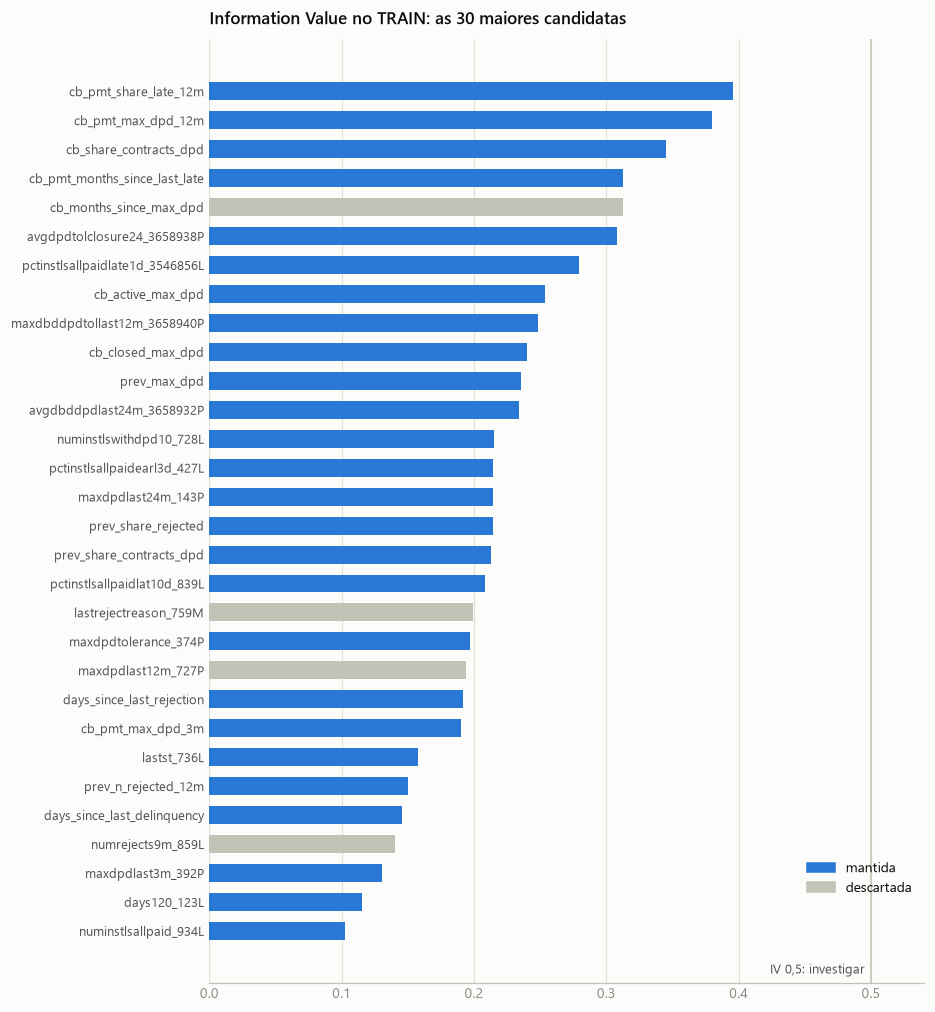

In [21]:
diagnostics = audit.feature_diagnostics(train_candidates, CANDIDATE_FEATURES, TARGET)
audit_table = catalog_frame().merge(diagnostics, on="feature")
periods = sorted(column.removeprefix("iv_") for column in diagnostics.columns if column.startswith("iv_2"))

ATTENTION_IV = 0.5      # regra de bolso do enunciado: acima disso, atenção especial
INVESTIGATION_IV = 0.3  # investigo uma a uma tudo o que fica acima disto
fig = plots.plot_iv_ranking(audit_table, top=30, attention_level=ATTENTION_IV)
plots.save_figure(fig, FIGURES_DIR / "iv_ranking_train.png")
print(f"IV no TRAIN: máximo {audit_table['iv'].max():.3f}, mediana {audit_table['iv'].median():.3f}; "
      f"candidatas com IV >= {ATTENTION_IV}: {(audit_table['iv'] >= ATTENTION_IV).sum()}; "
      f"com IV >= {INVESTIGATION_IV}: {(audit_table['iv'] >= INVESTIGATION_IV).sum()}; com IV < 0,02: {(audit_table['iv'] < 0.02).sum()}")

### 4.1 Disponibilidade e estabilidade da distribuição

feature,fonte,missing_share,fill_min_month,fill_max_month,psi_max,psi_max_quarter,decisao
cb_closed_max_dpd,credit_bureau_a_1,36.4%,0.0%,90.8%,1.87,2019Q1,manter
cb_years_since_first_credit,credit_bureau_a_1,25.5%,9.2%,97.0%,1.85,2019Q1,manter
cb_share_contracts_dpd,credit_bureau_a_1,25.6%,9.2%,96.9%,1.73,2019Q1,manter
cb_n_credits_12m,credit_bureau_a_1,25.5%,9.3%,97.0%,1.62,2019Q1,manter
cb_days_since_last_credit,credit_bureau_a_1,25.5%,9.2%,97.0%,1.60,2019Q1,manter
cb_pmt_share_late_12m,credit_bureau_a_2,28.5%,9.2%,93.7%,1.47,2019Q1,manter
cb_pmt_max_dpd_12m,credit_bureau_a_2,28.5%,9.2%,93.7%,1.46,2019Q1,manter
cb_pmt_max_dpd_3m,credit_bureau_a_2,31.3%,9.2%,89.6%,1.33,2019Q1,manter
cb_pmt_months_since_last_late,credit_bureau_a_2,49.7%,2.5%,72.9%,1.11,2019Q1,manter
cb_months_since_max_dpd,credit_bureau_a_1,49.8%,2.5%,72.8%,1.11,2019Q1,descartar


Fontes das features mantidas com PSI > 0,25: ['credit_bureau_a_1', 'credit_bureau_a_2', 'static_cb_0']
Maior PSI entre as mantidas de outras fontes: 0.13


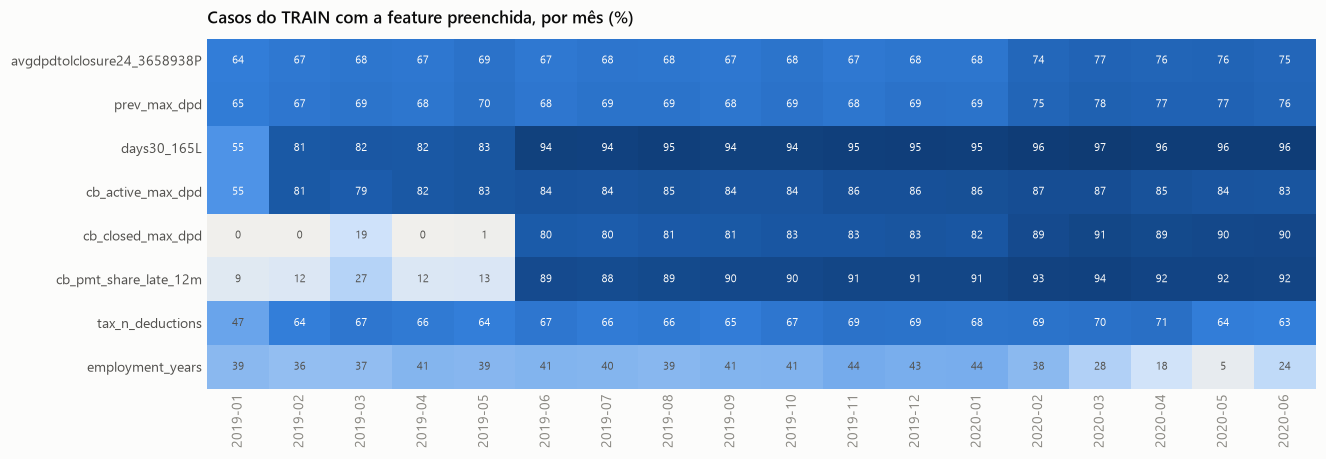

In [22]:
unstable = audit_table[audit_table["psi_max"] > 0.25].sort_values("psi_max", ascending=False)
display(unstable[["feature", "fonte", "missing_share", "fill_min_month", "fill_max_month", "psi_max", "psi_max_quarter", "decisao"]]
        .style.format({"missing_share": "{:.1%}", "fill_min_month": "{:.1%}", "fill_max_month": "{:.1%}", "psi_max": "{:.2f}"}).hide(axis="index"))
kept = audit_table[audit_table["decisao"] == KEEP]
print("Fontes das features mantidas com PSI > 0,25:", sorted(kept.loc[kept["psi_max"] > 0.25, "fonte"].unique()))
print(f"Maior PSI entre as mantidas de outras fontes: "
      f"{kept.loc[~kept['fonte'].str.startswith(('credit_bureau', 'static_cb')), 'psi_max'].max():.2f}")

fill_examples = ["avgdpdtolclosure24_3658938P", "prev_max_dpd", "days30_165L", "cb_active_max_dpd", "cb_closed_max_dpd",
                 "cb_pmt_share_late_12m", "tax_n_deductions", "employment_years"]
monthly_fill = (
    train_candidates.group_by(MONTH).agg([pl.col(feature).is_not_null().mean() for feature in fill_examples])
    .sort(MONTH).to_pandas().set_index(MONTH)
)
fig = plots.plot_share_heatmap(monthly_fill.T, "Casos do TRAIN com a feature preenchida, por mês (%)")
plots.save_figure(fig, FIGURES_DIR / "feature_fill_by_month.png")

In [23]:
def shares_by_quarter(feature: str) -> pd.DataFrame:
    """Parcela de cada categoria em cada trimestre do TRAIN (as mais frequentes)."""
    quarters = audit.quarter(train_candidates[MONTH])
    shares = pd.crosstab(train_candidates[feature].fill_null("(ausente)").to_pandas(), quarters.to_pandas(), normalize="columns")
    return shares.loc[shares.mean(axis=1).sort_values(ascending=False).index].head(5)


for feature in ("lastrejectreason_759M", "education_927M"):
    display(shares_by_quarter(feature).style.format("{:.1%}").set_caption(feature))

trimestre,2019Q1,2019Q2,2019Q3,2019Q4,2020Q1,2020Q2
lastrejectreason_759M,,,,,,
(ausente),67.0%,65.4%,64.4%,63.5%,56.1%,55.7%
P99_56_166,6.2%,15.7%,17.2%,18.1%,21.6%,23.8%
P94_109_143,23.0%,11.8%,9.6%,7.8%,7.7%,6.7%
P45_84_106,1.2%,3.5%,4.3%,5.0%,6.7%,6.6%
P198_131_9,0.9%,2.9%,3.9%,5.0%,7.1%,6.4%


trimestre,2019Q1,2019Q2,2019Q3,2019Q4,2020Q1,2020Q2
education_927M,,,,,,
(ausente),55.4%,50.7%,51.8%,49.5%,53.8%,61.4%
P97_36_170,27.4%,29.9%,29.4%,29.6%,28.5%,20.5%
P33_146_175,16.5%,18.5%,17.9%,20.0%,16.4%,10.4%
P106_81_188,0.5%,0.5%,0.4%,0.4%,0.8%,7.4%
P17_36_170,0.3%,0.4%,0.4%,0.4%,0.4%,0.3%


**Leitura.**

- As features com PSI alto são quase todas do **bureau**, com o pior trimestre em **2019Q1**: é o
  período em que o bureau cobre menos casos e não envia contratos encerrados (seção 2.4). O mapa
  de preenchimento mostra o degrau em junho de 2019; depois dele a disponibilidade é estável por
  13 meses seguidos. As consultas ao bureau (`days30_165L`, `days120_123L`) ficam no limite de
  0,25 só por causa da cobertura de janeiro de 2019. Entre as features mantidas, todas as que
  passam de 0,25 vêm do bureau; as de `static_0`, `person_1`, `applprev_1` e do registro fiscal
  ficam abaixo disso em todos os trimestres.
- `employment_years` oscila entre 5% e 44% de preenchimento conforme o mês: a coleta do dado não
  é confiável. **Descartada.**
- `lastrejectreason_759M` muda de composição continuamente (um código cai de 23% para 7% dos
  casos enquanto outro sobe de 6% para 24%): a política de recusa mudou durante o período e os
  códigos são anonimizados. **Descartada**; o histórico de recusas continua representado por três
  features com regra clara. `education_927M` muda no último trimestre e tem metade dos casos sem
  valor. **Descartada.**

**Consequência para a Semana 2:** os cinco primeiros meses de 2019 têm um regime de dados
diferente do resto (e do que se espera no OOT) para as features de bureau. Vale comparar o
treino com todos os meses contra o treino a partir de 2019-06.

### 4.2 Investigação individual das features mais fortes

Nenhuma candidata chega ao IV de 0,5 que o enunciado usa como alerta. Ainda assim, as seis com
IV acima de 0,3 ficam bem acima das demais e são investigadas uma a uma, com as cinco perguntas
do enunciado.

feature,fonte,regra_de_calculo,iv,iv_2019H1,iv_2019H2,iv_2020H1,decisao
cb_pmt_share_late_12m,credit_bureau_a_2,pagamentos com atraso > 0 / pagamentos reportados nos 12 meses até a decisão; nula se o bureau informa contratos encerrados mas não envia o detalhe deles,0.396,0.124,0.500,0.495,manter
cb_pmt_max_dpd_12m,credit_bureau_a_2,maior atraso (dias) nos pagamentos dos 12 meses até a decisão; nula se o bureau informa contratos encerrados mas não envia o detalhe deles,0.379,0.118,0.468,0.490,manter
cb_share_contracts_dpd,credit_bureau_a_1,contratos (ativos + encerrados) com atraso máximo > 0 / contratos com atraso conhecido; nula se o bureau informa contratos encerrados mas não envia o detalhe deles,0.345,0.114,0.457,0.403,manter
cb_pmt_months_since_last_late,credit_bureau_a_2,meses desde o último pagamento com atraso (nulo = nunca atrasou); nula se o bureau informa contratos encerrados mas não envia o detalhe deles,0.313,0.092,0.405,0.425,manter
cb_months_since_max_dpd,credit_bureau_a_1,meses desde o maior atraso de um contrato (ano/mês corrigidos); nula se o bureau informa contratos encerrados mas não envia o detalhe deles,0.312,0.087,0.404,0.430,descartar
avgdpdtolclosure24_3658938P,static_0,coluna original,0.308,0.280,0.324,0.310,manter


Maior taxa de default em uma faixa: 10.9% (TRAIN inteiro: 3.26%)


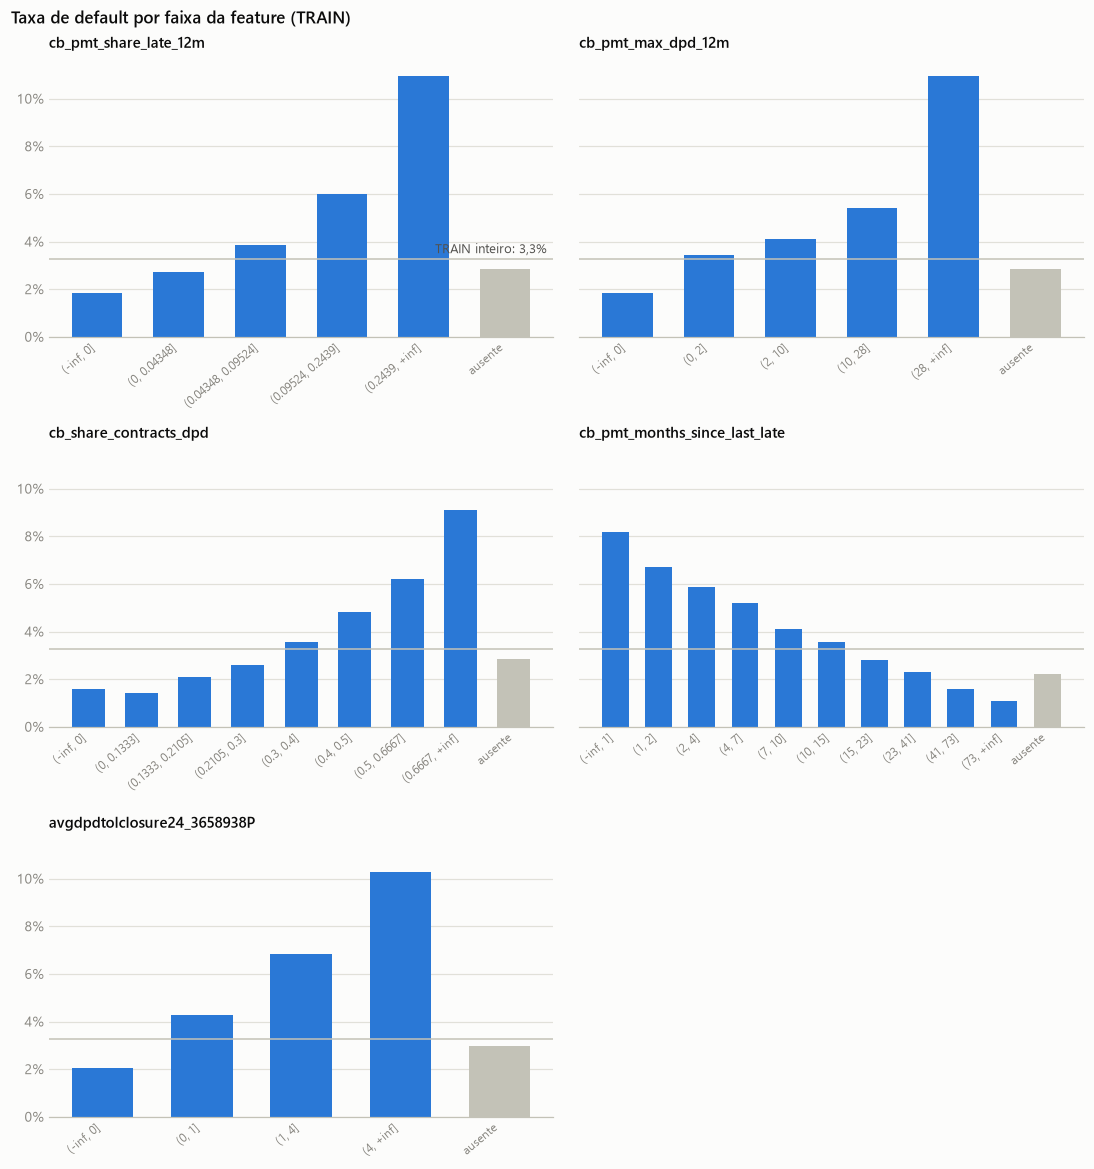

In [24]:
strongest = audit_table[audit_table["iv"] >= INVESTIGATION_IV].sort_values("iv", ascending=False)
assert set(strongest["feature"]) == {name for name in CANDIDATE_FEATURES if SPECS[name].leakage_risk == INVESTIGATED}
display(strongest[["feature", "fonte", "regra_de_calculo", "iv", *[f"iv_{period}" for period in periods], "decisao"]]
        .style.format({"iv": "{:.3f}", **{f"iv_{period}": "{:.3f}" for period in periods}}).hide(axis="index"))

labels = train_candidates[TARGET].to_numpy()
overall_rate = labels.mean()
kept_strongest = strongest.loc[strongest["decisao"] == KEEP, "feature"].tolist()
bin_tables = {feature: information_value(train_candidates[feature], labels)[1] for feature in kept_strongest}
fig = plots.plot_default_rate_by_bin(bin_tables, overall_rate, MISSING_LABEL)
plots.save_figure(fig, FIGURES_DIR / "default_rate_by_bin_top_features.png")
print(f"Maior taxa de default em uma faixa: {max(table['bad_rate'].max() for table in bin_tables.values()):.1%} "
      f"(TRAIN inteiro: {overall_rate:.2%})")

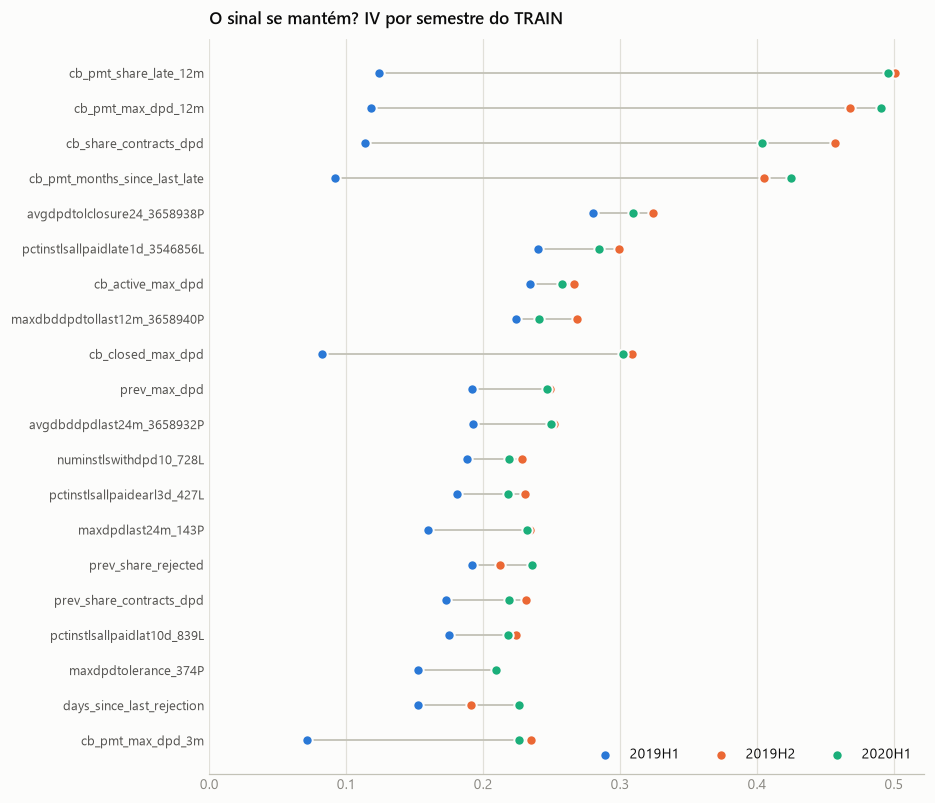

In [25]:
top_kept = audit_table[audit_table["decisao"] == KEEP].nlargest(20, "iv")["feature"].tolist()
fig = plots.plot_iv_by_period(audit_table, top_kept, periods)
plots.save_figure(fig, FIGURES_DIR / "iv_by_half_year.png")

**As cinco perguntas, para as seis features.** Cinco delas medem atraso em outras instituições
(bureau A) e uma mede o atraso médio com o próprio credor (`avgdpdtolclosure24_3658938P`).

| Pergunta do enunciado | Resposta | Evidência |
|---|---|---|
| 1. A informação existia em `date_decision`? | Sim | no calendário corrigido, nenhuma data do bureau ou de `static_0` passa da decisão (1.4) |
| 2. A agregação usou registro posterior? | Não | corte no código antes de agregar; só meses com pagamento reportado e até o mês da decisão; teste automático acrescenta registros futuros e exige features idênticas |
| 3. Contém o target, direta ou indiretamente? | Não | o contrato em análise não está no bureau nem nos pedidos anteriores (1.5); a pior faixa tem 11% de default, não algo perto de 100% |
| 4. O significado foi compreendido? | Sim | atraso passado prevê atraso futuro; a taxa de default cresce de forma monótona com a frequência e a gravidade do atraso e cai quanto mais antigo é o último atraso |
| 5. A força se mantém entre períodos? | Sim, quando o dado existe | IV parecido em 2019H2 e 2020H1; em 2019H1 é menor porque o bureau não enviava contratos encerrados (as features ficam nulas), não porque a relação mudou |

A feature interna tem o IV mais estável de todas (0,28 / 0,32 / 0,31). Conclusão: são fortes
porque o histórico de atraso é, de fato, o melhor preditor de inadimplência, não por vazamento.
`cb_months_since_max_dpd` é descartada por redundância (seção 4.3), não por suspeita.

### 4.3 Redundância e features sem sinal

In [26]:
REDUNDANCY_LEVEL = 0.85
pairs = audit.redundant_pairs(train_candidates, CANDIDATE_FEATURES, threshold=REDUNDANCY_LEVEL, seed=RANDOM_STATE)
pairs["decisao_a"] = pairs["feature_a"].map(lambda name: SPECS[name].decision)
pairs["decisao_b"] = pairs["feature_b"].map(lambda name: SPECS[name].decision)
display(pairs.style.format({"spearman_abs": "{:.3f}"}).hide(axis="index"))

weak = audit_table[audit_table["iv"] < 0.02].sort_values("iv")
display(weak[["feature", "fonte", "iv", *[f"iv_{period}" for period in periods], "decisao", "motivo"]]
        .style.format({"iv": "{:.3f}", **{f"iv_{period}": "{:.3f}" for period in periods}}).hide(axis="index"))

feature_a,feature_b,spearman_abs,decisao_a,decisao_b
totaldebt_9A,prev_outstanding_debt,0.999,manter,descartar
cb_pmt_max_dpd_12m,cb_pmt_share_late_12m,0.981,manter,manter
cb_active_debt,cb_debt_to_income,0.953,descartar,manter
days30_165L,cb_queries_30d_share,0.947,manter,descartar
cb_months_since_max_dpd,cb_pmt_months_since_last_late,0.941,descartar,manter
numcontrs3months_479L,prev_n_applications_3m,0.935,descartar,manter
totaldebt_9A,annuitynextmonth_57A,0.918,manter,descartar
annuitynextmonth_57A,prev_outstanding_debt,0.905,descartar,descartar
numrejects9m_859L,prev_n_rejected_12m,0.904,descartar,manter
prev_max_dpd,prev_share_contracts_dpd,0.902,manter,manter


feature,fonte,iv,iv_2019H1,iv_2019H2,iv_2020H1,decisao,motivo
debt_service_to_income,static_0 + credit_bureau_a_1 + person_1,0.001,0.006,0.001,0.007,descartar,sem sinal univariado em nenhum semestre do TRAIN e sem ganho sobre as partes que a compõem
mainoccupationinc_384A,person_1,0.002,0.001,0.003,0.008,manter,"mantida como denominador das razões de comprometimento, apesar do IV baixo"
cb_n_active_contracts,credit_bureau_a_1,0.002,0.006,0.001,0.009,descartar,sem sinal univariado em nenhum semestre do TRAIN
credtype_322L,static_0,0.003,0.001,0.005,0.005,manter,"mantida como segmento de produto, apesar do IV baixo"
annuity_to_income,static_0 + person_1,0.003,0.002,0.003,0.006,manter,"mantida pela hipótese clássica de capacidade de pagamento, apesar do IV baixo"
tax_amount_cv,tax_registry_a/b/c_1,0.004,0.003,0.007,0.018,descartar,o sinal só aparece nos meses do fornecedor B: depende de quem fornece o dado
cb_active_monthly_instalment,credit_bureau_a_1,0.005,0.013,0.008,0.013,descartar,sem sinal univariado em nenhum semestre do TRAIN
tax_n_employers,tax_registry_a/b/c_1,0.005,0.003,0.003,0.023,descartar,o sinal só aparece nos meses do fornecedor B: depende de quem fornece o dado
annuitynextmonth_57A,static_0,0.007,0.003,0.011,0.012,descartar,redundante com totaldebt_9A: mede o mesmo e fica a versão de dívida total
downpayment_share,static_0,0.008,0.007,0.007,0.012,descartar,quase sempre zero e sem sinal univariado


**Leitura.**

- **Redundância.** Quando uma feature autoral repete um agregado pronto do credor, fica uma só.
  `prev_outstanding_debt` é praticamente idêntica a `totaldebt_9A` (fica a original);
  `numrejects9m_859L` e `numcontrs3months_479L` repetem contagens que agora têm regra e corte
  auditáveis (ficam as autorais); a razão `cb_queries_30d_share` repete `days30_165L`. Pares que
  medem coisas diferentes ficam os dois, mesmo correlacionados: frequência e gravidade do atraso
  (`cb_pmt_share_late_12m` e `cb_pmt_max_dpd_12m`; `prev_share_contracts_dpd` e `prev_max_dpd`),
  pedidos e contratos. A seleção de features da Semana 2 decide entre eles com o modelo.
- **Sem sinal univariado.** As razões de comprometimento de renda (`annuity_to_income`,
  `credit_to_income`, `debt_service_to_income`) quase não separam bons e maus sozinhas. Minha
  hipótese (não dá para verificá-la com estes dados): a população já foi aprovada por uma
  política que limita esse comprometimento, e a renda é declarada pelo cliente. `annuity_to_income` e `credit_to_income` ficam, por
  serem as razões clássicas de capacidade de pagamento e poderem interagir com outras variáveis;
  `debt_service_to_income` sai (não acrescenta nada às partes e depende do bureau).
- **Registro fiscal.** Só a contagem de deduções tem sinal nos três semestres. O número de
  empregadores e a variação dos valores só mostram algum sinal em 2020H1, quando entra o
  fornecedor B: dependem de quem fornece o dado, e saem.

## 5. Decisões: tabela de auditoria e catálogo de features

Cada candidata recebe uma decisão com motivo. O IV apoia, mas os motivos de descarte são
redundância, disponibilidade instável ou falta de sinal em todos os períodos, sempre com a
evidência das seções anteriores. O catálogo completo (fonte, regra de cálculo, hipótese,
disponibilidade na decisão e como foi verificada, missing, IV, PSI, decisão) é gravado em
`reports/feature_catalog.csv`. Ele reúne as duas tabelas sugeridas pelo enunciado (seções 7.3 e
7.4): a das features autorais e a de auditoria com IV.

In [27]:
audit_columns = ["feature", "fonte", "tipo", "regra_de_calculo", "hipotese_de_negocio", "disponivel_na_decisao", "verificacao_temporal",
                 "risco_de_leakage", "missing_share", "fill_min_month", "fill_max_month", "psi_max", "psi_max_quarter",
                 "iv", "iv_missingness", *[f"iv_{period}" for period in periods], "decisao", "motivo"]
feature_catalog = audit_table[audit_columns].rename(columns={"missing_share": "missing_train", "iv": "iv_train"})
FEATURE_CATALOG_PATH.parent.mkdir(parents=True, exist_ok=True)
feature_catalog.to_csv(FEATURE_CATALOG_PATH, index=False)

summary = feature_catalog.groupby(["decisao", "tipo"]).size().unstack(fill_value=0)
summary["total"] = summary.sum(axis=1)
display(summary)

compact = ["feature", "fonte", "missing_train", "iv_train", "hipotese_de_negocio", "disponivel_na_decisao", "risco_de_leakage",
           "decisao", "motivo"]
display(feature_catalog.sort_values(["decisao", "iv_train"], ascending=[True, False])[compact]
        .style.format({"missing_train": "{:.1%}", "iv_train": "{:.3f}"}).hide(axis="index"))

tipo,autoral,original,total
decisao,,,
descartar,12,6,18
manter,30,26,56


feature,fonte,missing_train,iv_train,hipotese_de_negocio,disponivel_na_decisao,risco_de_leakage,decisao,motivo
cb_months_since_max_dpd,credit_bureau_a_1,49.8%,0.312,atraso grave recente pesa mais,sim,"baixo, após investigação individual (IV entre os maiores; notebook 02, seção 4.2)",descartar,redundante com cb_pmt_months_since_last_late: mede o mesmo e fica a versão do histórico mensal
lastrejectreason_759M,static_0,62.9%,0.199,o motivo da última recusa separa recusas por risco de recusas operacionais,sim,baixo,descartar,"a mistura de códigos muda continuamente ao longo do TRAIN e os códigos são anonimizados; o histórico de recusas fica com days_since_last_rejection, prev_share_rejected e prev_n_rejected_12m"
maxdpdlast12m_727P,static_0,20.8%,0.194,maior atraso em 12 meses,sim,baixo,descartar,redundante: fica entre as janelas de 3 e 24 meses e repete maxdbddpdtollast12m_3658940P
numrejects9m_859L,static_0,0.0%,0.141,recusas recentes,sim,baixo,descartar,redundante com prev_n_rejected_12m: mede o mesmo e fica a versão com regra e corte auditáveis
numcontrs3months_479L,static_0,0.0%,0.076,contratos nos últimos 3 meses,sim,baixo,descartar,redundante com prev_n_applications_3m: mede o mesmo e fica a versão com regra e corte auditáveis
cb_queries_30d_share,static_cb_0,22.2%,0.064,consultas concentradas no último mês indicam aceleração da busca por crédito,sim,baixo,descartar,redundante com days30_165L: mede o mesmo e fica a versão original
employment_years,person_1,61.4%,0.056,mais tempo no emprego = renda mais estável,sim,baixo,descartar,coleta instável: o preenchimento mensal oscila muito dentro do TRAIN
prev_outstanding_debt,applprev_1,20.7%,0.037,dívida em aberto com o credor,sim,baixo,descartar,redundante com totaldebt_9A: mede o mesmo e fica a versão original
education_927M,person_1,52.5%,0.034,escolaridade se associa a estabilidade de renda,sim,baixo,descartar,"metade dos casos sem valor, códigos anonimizados e composição que muda no último trimestre do TRAIN"
prev_max_credamount,applprev_1,30.6%,0.023,maior crédito que o cliente já assumiu,sim,baixo,descartar,"ingrediente de credit_to_prev_max_credit, que concentra a hipótese"


## 6. Master Table

A Master Table é a tabela candidata restrita às features mantidas, com as cinco colunas da
`train_base` e a coluna `split`. Antes de gravar, passa pelas checagens de `src/qa.py`, comparada
com a `train_base` **relida do disco**.

In [28]:
master = build_master_table(candidates, SELECTED_FEATURES)
qa = check_master_table(master, raw_base)
display(qa.style.hide(axis="index"))
assert_all_passed(qa)

elapsed = [name for name in SELECTED_FEATURES if "since" in name]
assert master.select(pl.col(elapsed).min()).min_horizontal().item() >= 0  # nenhuma recência negativa, em nenhuma linha
print(f"Features de recência: {len(elapsed)}; menor valor em toda a tabela: {master.select(pl.col(elapsed).min()).min_horizontal().item()}")

check,passed,detail
1 case_id = 1 linha,True,"1,526,659 linhas, 1,526,659 case_id distintos"
colunas-chave presentes,True,ausentes: nenhuma
mesma população da train_base,True,"0 casos perdidos, 0 casos criados"
chaves e target idênticos à train_base,True,0 casos com valor alterado
target binário e sem nulos,True,"valores: [0, 1]"
split definido para todos os casos,True,"valores: ['OOT', 'TEST', 'TRAIN']"
OOT = exatamente os meses do enunciado,True,0 casos fora da regra
nenhuma feature totalmente nula,True,nenhuma
nenhuma feature constante,True,nenhuma
nenhuma data bruta entre as features,True,nenhuma


Features de recência: 7; menor valor em toda a tabela: 0.0


In [29]:
MASTER_TABLE_PATH.parent.mkdir(parents=True, exist_ok=True)
master.write_parquet(MASTER_TABLE_PATH, compression="zstd")
MASTER_QA_PATH.parent.mkdir(parents=True, exist_ok=True)
qa.to_csv(MASTER_QA_PATH, index=False)

reloaded = pl.read_parquet(MASTER_TABLE_PATH)
assert reloaded.equals(master)
dtypes = pd.Series([str(dtype) for dtype in reloaded.select(SELECTED_FEATURES).dtypes]).value_counts()
print(f"{MASTER_TABLE_PATH.relative_to(MASTER_TABLE_PATH.parents[2])}: {reloaded.height:,} linhas x {reloaded.width} colunas "
      f"({len(SELECTED_FEATURES)} features: {sum(SPECS[name].kind == AUTHORED for name in SELECTED_FEATURES)} autorais), "
      f"{MASTER_TABLE_PATH.stat().st_size / 1e6:.0f} MB")
print("Tipos das features:", dtypes.to_dict())
display(reloaded.group_by(SPLIT).agg(pl.len().alias("casos"), pl.col(MONTH).min().alias("primeiro mês"), pl.col(MONTH).max().alias("último mês"))
        .sort("primeiro mês", "casos", descending=[False, True]).to_pandas().set_index(SPLIT))
display(reloaded.head(3).to_pandas())

data\processed\master_table.parquet: 1,526,659 linhas x 62 colunas (56 features: 30 autorais), 105 MB
Tipos das features: {'Float64': 41, 'UInt32': 7, 'Int64': 4, 'String': 3, 'Int32': 1}


,casos,primeiro mês,último mês
split,,,
TRAIN,1101135,201901,202006
TEST,275284,201901,202006
OOT,150240,202007,202010


,case_id,date_decision,WEEK_NUM,MONTH,target,split,credamount_770A,annuity_780A,pmtnum_254L,eir_270L,credtype_322L,totaldebt_9A,avgdpdtolclosure24_3658938P,pctinstlsallpaidlate1d_3546856L,pctinstlsallpaidlat10d_839L,pctinstlsallpaidearl3d_427L,maxdpdlast3m_392P,maxdpdlast24m_143P,maxdpdtolerance_374P,maxdbddpdtollast12m_3658940P,avgdbddpdlast24m_3658932P,numinstlswithdpd10_728L,numinstlsallpaid_934L,applications30d_658L,lastst_736L,...,prev_share_rejected,prev_days_since_last_application,prev_years_since_first_application,prev_n_applications_3m,prev_n_applications_12m,prev_n_rejected_12m,prev_max_dpd,prev_share_contracts_dpd,cb_n_closed_contracts,cb_active_overdue_amount,cb_active_max_dpd,cb_closed_max_dpd,cb_share_contracts_dpd,cb_years_since_first_credit,cb_days_since_last_credit,cb_n_credits_12m,cb_pmt_max_dpd_3m,cb_pmt_max_dpd_12m,cb_pmt_share_late_12m,cb_pmt_months_since_last_late,tax_n_deductions,annuity_to_income,credit_to_income,cb_debt_to_income,credit_to_prev_max_credit
0,0,2019-01-03,0,201901,0,TRAIN,30000.0,1917.6,24.0,0.4500,CAL,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,...,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.177556,2.777778,NaN,NaN
1,1,2019-01-03,0,201901,0,TRAIN,19999.8,3134.0,18.0,0.2999,CAL,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,...,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.313400,1.999980,NaN,NaN
2,2,2019-01-04,0,201901,0,TRAIN,78000.0,4937.0,36.0,0.4500,CAL,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,0.0,D,...,1.0,2116.0,5.793292,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.352643,5.571429,NaN,NaN


## 7. Checklist antes da modelagem (seção 12 do enunciado)

In [30]:
catalog = catalog_frame()
kept = catalog[catalog["decisao"] == KEEP]
passed = dict(zip(qa["check"], qa["passed"]))
checklist = pd.DataFrame([
    ("case_id é único na Master Table", passed["1 case_id = 1 linha"], "QA da seção 6"),
    ("target tem uma observação por case_id", passed["chaves e target idênticos à train_base"] and passed["target binário e sem nulos"], "QA da seção 6"),
    ("TRAIN, TEST e OOT definidos", passed["split definido para todos os casos"] and passed["OOT = exatamente os meses do enunciado"], "coluna split; src/split.py"),
    ("OOT não usado para selecionar features", True, "diagnósticos calculados em train_candidates (só TRAIN); do OOT só se leu o volume"),
    ("Sei explicar as famílias de tabelas escolhidas", True, "inventário do notebook 01 e reports/source_inventory.csv"),
    ("Não processei tabelas só por estarem disponíveis", True, "9 das 16 fontes usadas; 7 descartadas com motivo"),
    ("Features têm hipótese ou interpretação de negócio", bool(kept["hipotese_de_negocio"].str.len().gt(0).all()), "reports/feature_catalog.csv"),
    ("Pelo menos 10 features criadas", int((kept["tipo"] == AUTHORED).sum()) >= 10, f"{int((kept['tipo'] == AUTHORED).sum())} autorais mantidas"),
    ("Features temporais só usam informação até date_decision", bool((used["n_apos_corrigido"] == 0).all()), "auditoria da seção 1.4"),
    ("Agregações não usam registros posteriores à decisão", True, "corte no código + teste com registros futuros (tests/test_features.py)"),
    ("Missing, constantes e quase nulas investigados", passed["nenhuma feature constante"] and passed["nenhuma feature totalmente nula"], "notebook 01 (seção 6) e seção 4.1"),
    ("IV de seleção calculado só no TRAIN", True, "seção 4"),
    ("Features com IV muito alto investigadas", True, f"nenhuma acima de {ATTENTION_IV}; as {len(strongest)} acima de {INVESTIGATION_IV} investigadas (4.2)"),
    ("Nenhuma feature contém o resultado futuro do contrato", True, "seções 1.5 e 4.2"),
], columns=["item do enunciado", "ok", "evidência"])
assert checklist["ok"].all()
display(checklist.style.hide(axis="index"))

item do enunciado,ok,evidência
case_id é único na Master Table,True,QA da seção 6
target tem uma observação por case_id,True,QA da seção 6
"TRAIN, TEST e OOT definidos",True,coluna split; src/split.py
OOT não usado para selecionar features,True,diagnósticos calculados em train_candidates (só TRAIN); do OOT só se leu o volume
Sei explicar as famílias de tabelas escolhidas,True,inventário do notebook 01 e reports/source_inventory.csv
Não processei tabelas só por estarem disponíveis,True,9 das 16 fontes usadas; 7 descartadas com motivo
Features têm hipótese ou interpretação de negócio,True,reports/feature_catalog.csv
Pelo menos 10 features criadas,True,30 autorais mantidas
Features temporais só usam informação até date_decision,True,auditoria da seção 1.4
Agregações não usam registros posteriores à decisão,True,corte no código + teste com registros futuros (tests/test_features.py)


## Resumo

- **Master Table**: 1.526.659 casos, 1 linha por `case_id`, com `split` (TRAIN / TEST / OOT) e 56
  features (26 originais selecionadas e 30 autorais), gravada em `data/processed/master_table.parquet`.
- **Ponto de observação**: as datas das tabelas secundárias estão 14 dias (e os campos de ano/mês,
  1 mês) à frente do calendário de `date_decision`. Corrigido isso, nenhum registro é posterior à
  decisão; o corte temporal está no código e é coberto por teste.
- **Estabilidade**: o que mais ameaça a estabilidade não é o sinal das features, e sim a
  **disponibilidade das fontes externas**: fornecedores de registro fiscal que se revezam e um
  bureau que só envia o histórico completo a partir de 2019-06.
- **Para a Semana 2**: começar pela Regressão Logística; comparar treino com todos os meses contra
  treino a partir de 2019-06; medir AUC por mês e por semana no OOT; tratar no pipeline (ajustado
  só no TRAIN) os valores extremos e as categorias, que a Master Table guarda como vieram.